# KAT-Transformer option pricing — single-asset, cross-asset and multi-asset training

The pykan (KAN) section is removed. Only the **KAT-Transformer** (Kolmogorov-Arnold Transformer:
attention + a rational-activation KAN MLP, from Yang's `katransformer.py`) is used, extended to the
full training-regime study from Goswami, Rajani & Tanksale (2021):

| Regime | What it does | Paper |
|---|---|---|
| **Single-asset** | Train and test on the same asset (NIFTY50, BANKNIFTY) | Tables 4, 5 |
| **Cross-asset** | Train on asset A, test on asset B without retraining | Table 8 |
| **Multi-asset (combined)** | Train on pooled data, test on each asset out of sample | Table 9 |
| Benchmark | Black-Scholes with 20-day historical volatility | B-S rows |
| Diagnostics | Band coverage, actual-vs-predicted bias | Figs. 11, 14 |
| **COVID-period test** | Models trained on 2015-2017 tested on Jan 2019 - Apr 2020 (Q-Q shift, EM/rho vs B-S, IV band) | Sec. 7, Table 11, Figs. 17, 18 |

**Binning is shared across assets.** The bin cutoff (and `NUM_CLASSES`) is computed once on the
*pooled* 100·C/K distribution so a bin index means the same price band on both assets — required for
cross-asset and combined training to be valid, per the paper: *"Without uniform binning, it would not
be possible to combine or compare models trained on different datasets."*

**Note on the original notebook's train/test split.** It restricted both train and test to 2026
dates only, which throws away most of the history. That restriction is removed here in favor of the
paper's ordinary 70:30 chronological split over the full period; an optional `YEAR_FILTER` is left in
the config cell if you want the old behavior back for a quick run.

In [38]:
# from google.colab import drive
# drive.mount('/content/drive')

## KAT-Transformer setup

Clones the rational-activation kernels (`rational_kat_cu`, pure PyTorch fallback on CPU, Triton on
GPU) and the transformer definitions (`katransformer.py`, from the `kat` repo) if they are not
already present, then imports `KAN` (the rational-activation MLP block) and `Block` (attention + KAN,
wired together) unmodified.

In [39]:
import os, sys, shutil

if not os.path.exists("rational_kat_cu"):
    !git clone -q https://github.com/adamdad/rational_kat_cu.git
%pip install -q -e rational_kat_cu
%pip install -q timm

if not os.path.exists("katransformer.py"):
    # Prefer a copy already sitting in Drive, if you have one
    drive_copy = "/content/drive/MyDrive/data_files/katransformer.py"
    if os.path.exists(drive_copy):
        shutil.copy(drive_copy, "katransformer.py")
    else:
        if not os.path.exists("kat"):
            !git clone -q https://github.com/Adamdad/kat.git
        shutil.copy("kat/katransformer.py", "katransformer.py")

sys.path.insert(0, "rational_kat_cu")
assert os.path.exists("katransformer.py"), "katransformer.py still missing"
assert os.path.exists("rational_kat_cu"), "rational_kat_cu clone failed"
print("KAT-Transformer sources ready")

  error: subprocess-exited-with-error
  
  × Getting requirements to build editable did not run successfully.
  │ exit code: 1
  ╰─> [24 lines of output]
      Traceback (most recent call last):
        File "/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 389, in <module>
          main()
        File "/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 373, in main
          json_out["return_val"] = hook(**hook_input["kwargs"])
                                   ^^^^^^^^^^^^^^^^^^^^^^^^^^^^
        File "/home/rahulsm21/Documents/BTP/venv/lib/python3.12/site-packages/pip/_vendor/pyproject_hooks/_in_process/_in_process.py", line 157, in get_requires_for_build_editable
          return hook(config_settings)
                 ^^^^^^^^^^^^^^^^^^^^^
        File "/tmp/pip-build-env-o3imxqnv/overlay/lib/python3.12/site-packages/setuptools/bu

In [40]:
import warnings, math, copy
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from scipy.stats import norm

from katransformer import KAN, Block   # attention + rational-activation KAN MLP, untouched

warnings.filterwarnings('ignore')
pd.set_option('display.width', 180)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print("device:", device)

device: cuda


## 0. Configuration

In [41]:
DATA_DIR = 'data_files'
BOND_FILE = f"{DATA_DIR}/bond_yield.csv"

# Option files: a single path, a list of paths, or a glob ("data_files/NIFTY_20*.csv").
# Two layouts are auto-detected:
#   (a) NSE bhavcopy layout  INSTRUMENT,SYMBOL,EXPIRY_DT,STRIKE_PR,OPTION_TYP,OPEN,HIGH,LOW,CLOSE,
#       SETTLE_PR,CONTRACTS,VAL_INLAKH,OPEN_INT,CHG_IN_OI,TIMESTAMP   (your 2014-2018 data)
#   (b) the older 17-column layout the notebook used before.
# The bhavcopy layout has NO underlying value, so the spot file must cover the whole
# period (2014 .. Apr 2020): spot supplies the underlying close and the 20-day OHLC lookback.
ASSET_FILES = {
    'NIFTY50': {
        'options': f"{DATA_DIR}/NIFTY_raw.csv",
        'spot':    f"{DATA_DIR}/nifty_spot.csv",
        'symbol':  'NIFTY',          # SYMBOL value inside the bhavcopy file
    },
    'BANKNIFTY': {
        'options': f"{DATA_DIR}/BANKNIFTY_raw.csv",
        'spot':    f"{DATA_DIR}/banknifty_spot.csv",
        'symbol':  'BANKNIFTY',
    },
}

# ---- paper's date windows (Sec. 3): train Jan 2015 - Sep 2017, test Oct 2017 - Dec 2018 ----
USE_PAPER_DATE_SPLIT = True      # False -> old behaviour: 70:30 chronological split of whatever is loaded
DATA_START = '2015-01-01'        # option rows before this are dropped (2014 spot is still used for lookback)
TRAIN_END  = '2017-09-30'
DATA_END   = '2018-12-31'        # set both DATA_START / DATA_END to None to keep everything loaded

# ---- COVID-period test (Sec. 7): same pre-trained models, Jan 2019 - Apr 2020 data ----
RUN_COVID    = True
COVID_START  = '2019-01-01'
COVID_END    = '2020-04-30'
CRASH_START  = '2020-03-01'      # only used to split the COVID results into pre-crash / crash
COVID_APPROACHES = ['Approach III']          # paper uses III; add 'Approach I', 'Approach II' if wanted
COVID_FILES = {                  # same layouts as ASSET_FILES; point 'options' at the 2019-2020 file(s)
    'NIFTY50': {
        'options': f"{DATA_DIR}/NIFTY_covid_raw.csv",
        'spot':    f"{DATA_DIR}/nifty_spot.csv",
        'symbol':  'NIFTY',
    },
    'BANKNIFTY': {'options': f"{DATA_DIR}/BANKNIFTY_covid_raw.csv",
                  'spot':    f"{DATA_DIR}/banknifty_spot.csv", 'symbol': 'BANKNIFTY'},
}

# ---- filtering / binning (paper values) --------------------------------
LOOKBACK   = 20
DTE_MIN, DTE_MAX = 3, 45
ATM_BAND   = 0.04
W_BIN      = 0.1        # bin width on the 100*C/K scale
BIN_COVER  = 98.0        # percentile of pooled data below the overflow bin
TRAIN_FRAC = 0.70
OPTION_TYPE = 'CE'
SEED = 42

YEAR_FILTER = None       # e.g. 2026 to reproduce the original notebook's 2026-only split; None = full history

USE_ALL_OHLC_MEANS = True   # True -> paper's 17/19-feature Approach II/III; False -> mu_C-only variant

# ---- KAT-Transformer hyperparameters (same defaults as the original notebook) ----
EMBED_DIM  = 64
DEPTH      = 4
NUM_HEADS  = 4
MLP_RATIO  = 2.0
ACT_INIT   = "gelu"      # or "swish"
DROP_RATE  = 0.1
LR         = 1.2e-4
BATCH_SIZE = 32
MAX_EPOCHS = 40
PATIENCE   = 6            # early stopping on validation loss
VAL_FRAC   = 0.15
PRED_CHUNK = 2048

QUICK_MODE = False         # True -> tiny model / few epochs, for a fast end-to-end dry run
if QUICK_MODE:
    EMBED_DIM, DEPTH, NUM_HEADS = 16, 2, 2
    MAX_EPOCHS, PATIENCE = 4, 2

print("Assets:", list(ASSET_FILES))

Assets: ['NIFTY50', 'BANKNIFTY']


## 1. Data pipeline (per asset)

In [42]:
def load_bond_yields(path):
    bonds = pd.read_csv(path)
    bonds.columns = ['date', 'risk_free_rate', 'rf_open', 'rf_high', 'rf_low', 'change_pct']
    bonds['date'] = pd.to_datetime(bonds['date'], errors='coerce')
    for c in ['risk_free_rate', 'rf_open', 'rf_high', 'rf_low']:
        bonds[c] = pd.to_numeric(bonds[c].astype(str).str.replace(',', ''), errors='coerce')
    bonds.loc[bonds['risk_free_rate'] > 50, 'risk_free_rate'] = np.nan   # sentinel prints
    bonds = bonds.dropna(subset=['date']).sort_values('date')
    bonds['risk_free_rate'] = bonds['risk_free_rate'].ffill().bfill()
    full = pd.date_range(bonds['date'].min(), bonds['date'].max(), freq='D')
    return (bonds.set_index('date')[['risk_free_rate']]
                 .reindex(full).rename_axis('date').ffill().reset_index())


def load_spot(path):
    spot = pd.read_csv(path)
    if 'TIMESTAMP' in spot.columns:
        spot = spot.drop(columns=['TIMESTAMP'])
    spot.columns = ['date', 'spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']
    spot['date'] = pd.to_datetime(spot['date'], errors='coerce')
    for c in ['spot_close', 'spot_high', 'spot_low', 'spot_open', 'spot_volume']:
        spot[c] = pd.to_numeric(spot[c].astype(str).str.replace(',', ''), errors='coerce')
    return spot.dropna(subset=['date']).sort_values('date').reset_index(drop=True)


import glob

def _parse_dates(col):
    """Handles '27-DEC-2018', '27-Dec-2018', '2018-12-27' and day-first fallbacks in one column."""
    s = col.astype(str).str.strip()
    out = pd.to_datetime(s, format='%d-%b-%Y', errors='coerce')
    m = out.isna()
    if m.any():
        out[m] = pd.to_datetime(s[m], format='%Y-%m-%d', errors='coerce')
    m = out.isna()
    if m.any():
        out[m] = pd.to_datetime(s[m], errors='coerce', dayfirst=True)
    return out


def _expand(paths):
    if isinstance(paths, (list, tuple)):
        files = [f for p in paths for f in (sorted(glob.glob(p)) or [p])]
    else:
        files = sorted(glob.glob(paths)) or [paths]
    return files


# bhavcopy column -> internal name
BHAV_COLS = {'INSTRUMENT': 'instrument', 'SYMBOL': 'symbol', 'EXPIRY_DT': 'expiry',
             'STRIKE_PR': 'strike', 'OPTION_TYP': 'option_type', 'OPEN': 'open', 'HIGH': 'high',
             'LOW': 'low', 'CLOSE': 'close', 'SETTLE_PR': 'settle_price', 'CONTRACTS': 'contracts',
             'VAL_INLAKH': 'turnover_lakhs', 'OPEN_INT': 'open_interest',
             'CHG_IN_OI': 'change_in_oi', 'TIMESTAMP': 'date'}
OLD_COLS = ['symbol', 'date', 'expiry', 'option_type', 'strike',
            'open', 'high', 'low', 'close', 'ltp', 'settle_price',
            'contracts', 'turnover_lakhs', 'premium_turnover_lakhs',
            'open_interest', 'change_in_oi', 'underlying']
NUM_COLS = ['strike', 'open', 'high', 'low', 'close', 'ltp', 'settle_price', 'contracts',
            'turnover_lakhs', 'premium_turnover_lakhs', 'open_interest', 'change_in_oi', 'underlying']


def _read_one_option_file(path, symbol=None):
    raw = pd.read_csv(path, low_memory=False)
    raw = raw.drop(columns=[c for c in raw.columns if str(c).startswith('Unnamed')], errors='ignore')
    raw.columns = [str(c).strip() for c in raw.columns]

    if {'TIMESTAMP', 'EXPIRY_DT', 'STRIKE_PR'} <= set(c.upper() for c in raw.columns):      # (a) bhavcopy
        raw.columns = [c.upper() for c in raw.columns]
        opt = raw.rename(columns=BHAV_COLS)[[v for v in BHAV_COLS.values() if v in raw.rename(columns=BHAV_COLS)]]
        if 'instrument' in opt:                       # keep index options only (drops OPTSTK / OPTFUT rows)
            opt = opt[opt['instrument'].astype(str).str.strip().str.upper() == 'OPTIDX']
        if symbol is not None:                        # one file can hold NIFTY, BANKNIFTY, FINNIFTY ...
            opt = opt[opt['symbol'].astype(str).str.strip().str.upper() == symbol.upper()]
        for c in ('ltp', 'premium_turnover_lakhs', 'underlying'):
            opt[c] = np.nan                           # not in this layout; underlying comes from the spot file
    else:                                             # (b) legacy 17-column layout, positional
        opt = raw.copy()
        opt.columns = OLD_COLS
    return opt


def load_options(paths, symbol=None):
    opt = pd.concat([_read_one_option_file(p, symbol) for p in _expand(paths)], ignore_index=True)
    opt['date'] = _parse_dates(opt['date'])
    opt['expiry'] = _parse_dates(opt['expiry'])
    for c in NUM_COLS:
        opt[c] = pd.to_numeric(opt[c].astype(str).str.replace(',', ''), errors='coerce')
    opt['option_type'] = opt['option_type'].astype(str).str.strip().str.upper()
    opt = opt.dropna(subset=['date', 'expiry', 'strike'])
    return opt.drop_duplicates(subset=['date', 'expiry', 'option_type', 'strike'], keep='last')


def build_lookback_frame(spot, lookback=LOOKBACK):
    lb = spot[['date', 'spot_open', 'spot_high', 'spot_low', 'spot_close']].copy()
    for lag in range(1, lookback + 1):
        lb[f'und_open_lag{lag}']  = lb['spot_open'].shift(lag)
        lb[f'und_high_lag{lag}']  = lb['spot_high'].shift(lag)
        lb[f'und_low_lag{lag}']   = lb['spot_low'].shift(lag)
        lb[f'und_close_lag{lag}'] = lb['spot_close'].shift(lag)
    return (lb.drop(columns=['spot_open', 'spot_high', 'spot_low', 'spot_close'])
              .dropna().reset_index(drop=True))


def build_asset_dataset(name, files, bonds, verbose=True, date_min=None, date_max=None):
    counts = {}
    opt = load_options(files['options'], symbol=files.get('symbol'))
    counts['raw'] = len(opt)
    spot = load_spot(files['spot'])

    opt = opt.merge(spot[['date', 'spot_close']], on='date', how='left')
    opt['underlying'] = opt['spot_close']
    opt = opt.drop(columns=['spot_close']).dropna(subset=['underlying'])

    if OPTION_TYPE is not None:
        opt = opt[opt['option_type'] == OPTION_TYPE]
    opt = opt[(opt['contracts'].fillna(0) > 0) & (opt['turnover_lakhs'].fillna(0) > 0)]

    opt['days_to_expiry'] = (opt['expiry'] - opt['date']).dt.days
    opt = opt[(opt['days_to_expiry'] >= DTE_MIN) & (opt['days_to_expiry'] <= DTE_MAX)]

    opt['moneyness_gap'] = (1 - opt['underlying'] / opt['strike']).abs()
    opt = opt[opt['moneyness_gap'] <= ATM_BAND]

    opt = opt.sort_values(['expiry', 'option_type', 'strike', 'date'])
    opt['prev_day_close'] = opt.groupby(['expiry', 'option_type', 'strike'])['close'].shift(1)
    opt = opt.dropna(subset=['prev_day_close'])

    opt = opt.merge(build_lookback_frame(spot), on='date', how='inner')
    opt = opt.merge(spot, on='date', how='left')
    opt = opt.merge(bonds, on='date', how='left')
    opt['risk_free_rate'] = opt['risk_free_rate'].ffill().bfill()
    opt['time_to_maturity_yrs'] = opt['days_to_expiry'] / 365.0
    opt['asset'] = name

    if YEAR_FILTER is not None:
        opt = opt[opt['date'].dt.year == YEAR_FILTER]
    # date window is applied LAST so earlier rows still feed prev_day_close and the spot lookback
    if date_min is not None:
        opt = opt[opt['date'] >= pd.Timestamp(date_min)]
    if date_max is not None:
        opt = opt[opt['date'] <= pd.Timestamp(date_max)]

    opt = opt.sort_values('date').reset_index(drop=True)
    counts['filtered'] = len(opt)
    if verbose:
        print(f"[{name}] raw={counts['raw']:,}  filtered={counts['filtered']:,}  "
              f"({opt['date'].min().date()} to {opt['date'].max().date()})")
    return opt, counts

In [43]:
bonds = load_bond_yields(BOND_FILE)

DATA, COUNTS = {}, {}
for name, files in ASSET_FILES.items():
    DATA[name], COUNTS[name] = build_asset_dataset(name, files, bonds,
                                              date_min=DATA_START, date_max=DATA_END)

ASSETS = list(DATA)
MULTI_ASSET = len(ASSETS) >= 2
print("\nassets loaded:", ASSETS, "| multi-asset regimes enabled:", MULTI_ASSET)

[NIFTY50] raw=1,087,289  filtered=16,333  (2015-01-02 to 2018-12-24)
[BANKNIFTY] raw=360,162  filtered=24,898  (2015-01-01 to 2018-12-24)

assets loaded: ['NIFTY50', 'BANKNIFTY'] | multi-asset regimes enabled: True


## 2. Shared binning across assets

In [44]:
pooled_ratio = pd.concat([100 * d['close'] / d['strike'] for d in DATA.values()], ignore_index=True)
pooled_raw = np.ceil(pooled_ratio / W_BIN).astype(int).clip(lower=1)

counts_sorted = pooled_raw.value_counts().sort_index()
cum_pct = counts_sorted.cumsum() / counts_sorted.sum() * 100
CUTOFF_BIN = int(cum_pct[cum_pct <= BIN_COVER].index.max())
NUM_CLASSES = 50

print(f"Pooled data: bins 1-{CUTOFF_BIN} cover ~{BIN_COVER}%  ->  NUM_CLASSES = {NUM_CLASSES}")

for name, d in DATA.items():
    d['output_ratio'] = 100 * d['close'] / d['strike']
    d['bin_label_raw'] = np.ceil(d['output_ratio'] / W_BIN).astype(int).clip(lower=1)
    d['bin_label'] = np.where(d['bin_label_raw'] > CUTOFF_BIN, NUM_CLASSES, d['bin_label_raw'])
    share = 100 * (d['bin_label'] == NUM_CLASSES).mean()
    print(f"[{name}] bins {d['bin_label'].min()}-{d['bin_label'].max()}, "
          f"overflow bin holds {share:.2f}% of rows")

Pooled data: bins 1-44 cover ~98.0%  ->  NUM_CLASSES = 50
[NIFTY50] bins 1-50, overflow bin holds 2.41% of rows
[BANKNIFTY] bins 1-50, overflow bin holds 2.55% of rows


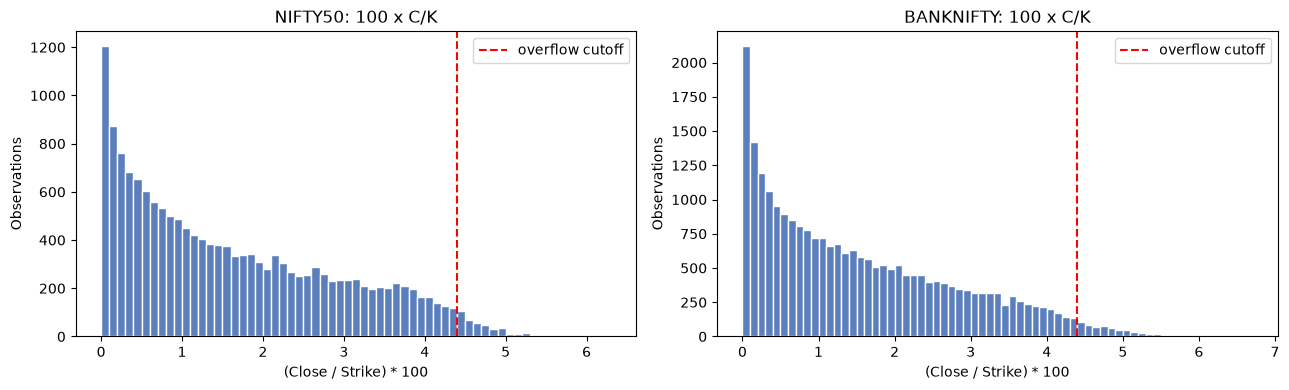

In [45]:
fig, axes = plt.subplots(1, len(DATA), figsize=(6.5*len(DATA), 4), squeeze=False)
for ax, (name, d) in zip(axes[0], DATA.items()):
    ax.hist(d['output_ratio'], bins=np.arange(0, d['output_ratio'].max()+W_BIN, W_BIN),
            color='#5b7fbd', edgecolor='white')
    ax.axvline(CUTOFF_BIN * W_BIN, color='red', ls='--', label='overflow cutoff')
    ax.set_xlabel('(Close / Strike) * 100'); ax.set_ylabel('Observations')
    ax.set_title(f'{name}: 100 x C/K'); ax.legend()
plt.tight_layout(); plt.show()

## 3. Feature sets — Approaches I, II, III

Identical columns and order for every asset, so a model trained on one asset can score another
asset's matrix directly.

In [46]:
def log_returns_from_lookback(df, field, lookback=LOOKBACK):
    cols_chrono = [f'und_{field}_lag{i}' for i in range(lookback, 0, -1)]
    return np.diff(np.log(df[cols_chrono].values.astype(float)), axis=1)


def signed_sqrt(x):
    out = np.zeros_like(x)
    m = x != 0
    out[m] = x[m] / np.sqrt(np.abs(x[m]))
    return out


def contract_block(df):
    return pd.DataFrame({
        'moneyness':        (df['underlying'] / df['strike']).values,
        'time_to_maturity': df['days_to_expiry'].values.astype(float),
        'interest_rate':    df['risk_free_rate'].values.astype(float),
    }, index=df.index)


def build_approach1(df):
    os_close = np.sort(log_returns_from_lookback(df, 'close'), axis=1)
    X = pd.DataFrame(os_close, columns=[f'os_close_{i+1}' for i in range(os_close.shape[1])],
                     index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach2(df):
    lr_o = log_returns_from_lookback(df, 'open')
    lr_h = log_returns_from_lookback(df, 'high')
    lr_l = log_returns_from_lookback(df, 'low')
    lr_c = log_returns_from_lookback(df, 'close')

    stack = np.stack([lr_o, lr_h, lr_l, lr_c], axis=1)
    centered = stack - stack.mean(axis=2, keepdims=True)
    cov = np.einsum('nik,njk->nij', centered, centered) / (stack.shape[2] - 1)
    cov_t = signed_sqrt(cov)

    labels = ['O', 'H', 'L', 'C']
    cov_cols = {f'cov_{labels[i]}{labels[j]}': cov_t[:, i, j]
                for i in range(4) for j in range(i + 1)}

    means = ({'mu_O': lr_o.mean(axis=1), 'mu_H': lr_h.mean(axis=1),
              'mu_L': lr_l.mean(axis=1), 'mu_C': lr_c.mean(axis=1)}
             if USE_ALL_OHLC_MEANS else {'mu_C': lr_c.mean(axis=1)})

    X = pd.DataFrame({**means, **cov_cols}, index=df.index)
    X = pd.concat([X, contract_block(df)], axis=1)
    X['bin_label'] = df['bin_label'].values
    return X


def build_approach3(df):
    X = build_approach2(df).drop(columns=['bin_label'])
    X['prev_option_price_scaled'] = (df['prev_day_close'] / df['strike']).values
    lookback_close_cols = [f'und_close_lag{i}' for i in range(1, LOOKBACK + 1)]
    X['mean_moneyness'] = (df[lookback_close_cols].mean(axis=1) / df['strike']).values
    X['bin_label'] = df['bin_label'].values
    return X


APPROACH_BUILDERS = {'Approach I': build_approach1,
                     'Approach II': build_approach2,
                     'Approach III': build_approach3}
APPROACHES = list(APPROACH_BUILDERS)

In [47]:
FEATURES = {name: {ap: fn(d) for ap, fn in APPROACH_BUILDERS.items()}
            for name, d in DATA.items()}

print("Feature counts (excl. label):")
print(pd.DataFrame({ap: {n: FEATURES[n][ap].shape[1]-1 for n in FEATURES} for ap in APPROACHES}))

for ap in APPROACHES:
    cols = [list(FEATURES[n][ap].columns) for n in ASSETS]
    assert all(c == cols[0] for c in cols), f"column mismatch in {ap}"
print("\nColumn alignment across assets: OK")

Feature counts (excl. label):
           Approach I  Approach II  Approach III
NIFTY50            22           17            19
BANKNIFTY          22           17            19

Column alignment across assets: OK


## 4. Train / test split and metrics

In [48]:
SPLIT = {}
for name, d in DATA.items():
    if USE_PAPER_DATE_SPLIT:                      # paper: Jan 2015 - Sep 2017 train | Oct 2017 - Dec 2018 test
        cutoff = pd.Timestamp(TRAIN_END)
        train_mask = (d['date'] <= cutoff).values
        test_mask  = (d['date'] > cutoff).values
    else:                                         # 70:30 chronological split by distinct dates
        dates = np.sort(d['date'].unique())
        cutoff = pd.Timestamp(dates[int(len(dates) * TRAIN_FRAC) - 1])
        train_mask = (d['date'] <= cutoff).values
        test_mask  = (d['date'] > cutoff).values
    SPLIT[name] = {'train': train_mask, 'test': test_mask, 'cutoff': cutoff}
    COUNTS[name].update(train=int(train_mask.sum()), test=int(test_mask.sum()))
    print(f"[{name}] cutoff {cutoff.date()} | train {COUNTS[name]['train']:,} | test {COUNTS[name]['test']:,}")

print()
print(pd.DataFrame(COUNTS).loc[['raw', 'filtered', 'train', 'test']])


[NIFTY50] cutoff 2017-09-30 | train 10,323 | test 6,010
[BANKNIFTY] cutoff 2017-09-30 | train 13,975 | test 10,923

          NIFTY50  BANKNIFTY
raw       1087289     360162
filtered    16333      24898
train       10323      13975
test         6010      10923


In [49]:
def em_metric(actual, pred, bin_width=W_BIN):
    return bin_width * np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)))

def rho_metric(actual, pred):
    return np.mean(np.abs(np.asarray(actual, float) - np.asarray(pred, float)) > 2)

def acc_metric(actual, pred):
    return np.mean(np.round(np.asarray(pred, float)) == np.asarray(actual, float))

def split_xy(feat_df, mask):
    cols = [c for c in feat_df.columns if c != 'bin_label']
    return (feat_df.loc[mask, cols].values.astype(np.float32),
            feat_df.loc[mask, 'bin_label'].values.astype(np.int64),
            cols)

## 5. KAT-Transformer model and training

`FeatureTokenizer` + `KATTabularTransformer` are unchanged from the original notebook: each tabular
feature gets its own learned linear embedding (FT-Transformer style), a `[CLS]` token is prepended,
and the sequence runs through `Block` (attention + the rational-activation KAN MLP) from
`katransformer.py`.

Training now uses a held-out validation split with early stopping, so the same routine works whether
the training set has 7,000 rows (single-asset) or 14,000 (combined) without hand-tuning an epoch
count per regime.

In [50]:
EMBED_DIM, DEPTH, NUM_HEADS, MLP_RATIO = 32, 2, 4, 2.0   # was 64 / 4 (and the old code ignored them)
DROP_RATE = 0.1

TOKENIZER  = 'periodic'   # 'linear' reproduces the old tokenizer
N_FREQ     = 8
FREQ_SIGMA = 0.1          # main knob: 0.05-0.2 smooth, larger overfits
USE_WIDE   = True         # linear skip from raw features to logits
CLIP       = 5.0

LABEL_SIGMA, DECODE, ENSEMBLE_SEEDS, WEIGHT_DECAY = 1.0, 'median', 3, 1e-2

In [51]:
import math

for _k, _v in dict(TOKENIZER='periodic', N_FREQ=8, FREQ_SIGMA=0.1, USE_WIDE=True).items():
    globals().setdefault(_k, _v)


class FeatureTokenizer(nn.Module):
    """(B, F) -> (B, F, D). 'linear' = original per-feature affine embedding.
    'periodic' = sin/cos features of each scalar (learned frequencies) + raw value,
    projected per feature, so a feature's token can be a curved function of its value."""
    def __init__(self, n_features, embed_dim, kind='periodic', n_freq=8, freq_sigma=0.1):
        super().__init__()
        self.kind = kind
        self.bias = nn.Parameter(torch.zeros(n_features, embed_dim))
        if kind == 'linear':
            self.weight = nn.Parameter(torch.randn(n_features, embed_dim) * 0.02)
        else:
            self.freq = nn.Parameter(torch.randn(n_features, n_freq) * freq_sigma)
            k = 2 * n_freq + 1
            self.proj = nn.Parameter(torch.randn(n_features, k, embed_dim) / math.sqrt(k))

    def forward(self, x):                                       # x: (B, F)
        if self.kind == 'linear':
            return x.unsqueeze(-1) * self.weight + self.bias
        v = 2 * math.pi * x.unsqueeze(-1) * self.freq           # (B, F, n_freq)
        f = torch.cat([torch.sin(v), torch.cos(v), x.unsqueeze(-1)], dim=-1)
        return torch.einsum('bfk,fkd->bfd', f, self.proj) + self.bias


class KATTabularTransformer(nn.Module):
    def __init__(self, n_features, num_classes, embed_dim=32, depth=2, num_heads=4,
                 mlp_ratio=2.0, act_init="gelu", drop_rate=0.1,
                 tokenizer='periodic', n_freq=8, freq_sigma=0.1, use_wide=True):
        super().__init__()
        self.tokenizer = FeatureTokenizer(n_features, embed_dim, tokenizer, n_freq, freq_sigma)
        self.cls_token = nn.Parameter(torch.zeros(1, 1, embed_dim))
        self.tok_drop  = nn.Dropout(drop_rate)
        # no pos_embed: each feature already has its own tokenizer weights, so it knows which feature it is

        self.blocks = nn.ModuleList([
            Block(dim=embed_dim, num_heads=num_heads, mlp_ratio=mlp_ratio, qkv_bias=True,
                  proj_drop=drop_rate, attn_drop=drop_rate,
                  mlp_layer=KAN, act_init=act_init)
            for _ in range(depth)
        ])
        self.norm = nn.LayerNorm(embed_dim)
        self.head = nn.Linear(embed_dim, num_classes)

        self.wide = None
        if use_wide:                                            # linear skip: raw features -> logits
            self.wide = nn.Linear(n_features, num_classes)
            nn.init.zeros_(self.wide.weight); nn.init.zeros_(self.wide.bias)

        nn.init.trunc_normal_(self.cls_token, std=0.02)

    def forward(self, x):                                       # x: (B, F)
        tokens = self.tokenizer(x)
        cls = self.cls_token.expand(x.shape[0], -1, -1)
        tokens = self.tok_drop(torch.cat([cls, tokens], dim=1))
        for blk in self.blocks:
            tokens = blk(tokens)
        out = self.head(self.norm(tokens)[:, 0])
        if self.wide is not None:
            out = out + self.wide(x)
        return out

In [52]:
import torch.nn.functional as F

for _k, _v in dict(LABEL_SIGMA=1.0, DECODE='median', ENSEMBLE_SEEDS=3,
                   WEIGHT_DECAY=1e-2, CLIP=5.0).items():
    globals().setdefault(_k, _v)


def standardize_fit(X):
    mean = X.mean(axis=0, keepdims=True)
    std = X.std(axis=0, keepdims=True)
    std[std < 1e-8] = 1e-8
    return mean, std


def prep(X, mean, std):
    return np.clip((X - mean) / std, -CLIP, CLIP)     # crash-period inputs sit far outside training range


def split_val(X, y, frac=VAL_FRAC, seed=SEED, dates=None):
    """Chronological hold-out (last `frac` of dates). Same-day contracts are near-duplicates,
    so a random split leaks. If `dates` is None, rows are assumed date-sorted."""
    if dates is None:
        cut = int(X.shape[0] * (1 - frac))
        return X[:cut], y[:cut], X[cut:], y[cut:]
    t = np.asarray(dates).astype('datetime64[ns]').astype('int64')
    is_val = t > np.quantile(t, 1 - frac)
    return X[~is_val], y[~is_val], X[is_val], y[is_val]


def soft_ce(logits, y_idx, sigma=None):
    sigma = LABEL_SIGMA if sigma is None else sigma
    if sigma <= 0:
        return F.cross_entropy(logits, y_idx)
    k = torch.arange(logits.shape[1], device=logits.device, dtype=logits.dtype).unsqueeze(0)
    q = torch.exp(-0.5 * ((k - y_idx.unsqueeze(1).to(logits.dtype)) / sigma) ** 2)
    q = q / q.sum(dim=1, keepdim=True)
    return -(q * F.log_softmax(logits, dim=1)).sum(dim=1).mean()


def _fit_one(X_full, y_full, num_classes, seed, dates=None, tag="", verbose=False):
    X_tr_raw, y_tr, X_val_raw, y_val = split_val(X_full, y_full, VAL_FRAC, seed, dates)
    mean, std = standardize_fit(X_tr_raw)
    X_tr, X_val = prep(X_tr_raw, mean, std), prep(X_val_raw, mean, std)

    torch.manual_seed(seed)
    loader = DataLoader(TensorDataset(torch.tensor(X_tr, dtype=torch.float32),
                                      torch.tensor(y_tr - 1, dtype=torch.long)),
                        batch_size=BATCH_SIZE, shuffle=True)
    X_val_t = torch.tensor(X_val, dtype=torch.float32).to(device)
    y_val_t = torch.tensor(y_val - 1, dtype=torch.long).to(device)

    model = KATTabularTransformer(
        n_features=X_tr.shape[1], num_classes=num_classes,
        embed_dim=EMBED_DIM, depth=DEPTH, num_heads=NUM_HEADS, mlp_ratio=MLP_RATIO,
        act_init=ACT_INIT, drop_rate=DROP_RATE,
        tokenizer=TOKENIZER, n_freq=N_FREQ, freq_sigma=FREQ_SIGMA, use_wide=USE_WIDE).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=LR, weight_decay=WEIGHT_DECAY)

    best, best_state, bad = float('inf'), None, 0
    for epoch in range(1, MAX_EPOCHS + 1):
        model.train(); tot = 0.0
        for xb, yb in loader:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = soft_ce(model(xb), yb)
            loss.backward(); opt.step()
            tot += loss.item() * xb.size(0)
        model.eval()
        with torch.no_grad():
            vl = soft_ce(model(X_val_t), y_val_t).item()
        if verbose and (epoch % 5 == 0 or epoch == 1):
            print(f"    {tag} seed {seed} ep {epoch:3d} train {tot/len(y_tr):.4f} val {vl:.4f}")
        if vl < best - 1e-4:
            best, best_state, bad = vl, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1
            if bad >= PATIENCE: break
    if best_state is not None:
        model.load_state_dict(best_state)
    return {'model': model, 'mean': mean, 'std': std, 'num_classes': num_classes,
            'n_features': X_tr.shape[1], 'val_loss': best, 'epochs_run': epoch}


def fit_kat(X_train_full, y_train_full, num_classes=None, seed=SEED, tag="",
            verbose=False, dates=None):
    num_classes = num_classes or NUM_CLASSES
    members = [_fit_one(X_train_full, y_train_full, num_classes, seed + 1000 * i, dates, tag, verbose)
               for i in range(ENSEMBLE_SEEDS)]
    return {'members': members, 'num_classes': num_classes,
            'val_loss': float(np.mean([m['val_loss'] for m in members])),
            'epochs_run': [m['epochs_run'] for m in members]}


@torch.no_grad()
def predict_proba(bundle, X_raw, chunk=PRED_CHUNK):
    members = bundle.get('members', [bundle])
    total = None
    for m in members:
        m['model'].eval()
        Xs = prep(X_raw, m['mean'], m['std'])
        p = np.concatenate([
            torch.softmax(m['model'](torch.tensor(Xs[s:s+chunk], dtype=torch.float32).to(device)),
                          dim=1).cpu().numpy()
            for s in range(0, len(Xs), chunk)])
        total = p if total is None else total + p
    return total / len(members)


def decode_bins(probs, mode=None):
    mode = mode or DECODE
    if mode == 'argmax':
        return probs.argmax(axis=1) + 1
    return (probs.cumsum(axis=1) >= 0.5).argmax(axis=1) + 1      # median bin


def predict_bins(bundle, X_raw, chunk=PRED_CHUNK):
    return decode_bins(predict_proba(bundle, X_raw, chunk))


def score(bundle, X_raw, y_true):
    pred = predict_bins(bundle, X_raw)
    return pred, {'EM': em_metric(y_true, pred), 'rho': rho_metric(y_true, pred),
                  'A': acc_metric(y_true, pred)}

## Experiment 1 — Single-asset training (Tables 4 and 5)

One KAT-Transformer per (asset, approach), trained and tested on the same asset. Bundles are kept in
`SINGLE_BUNDLES` and reused by Experiments 3 and 4 — no retraining.

In [53]:
SINGLE_BUNDLES, SINGLE_PRED = {}, {}
single_rows = []

def run_single_asset(name):
    for ap in APPROACHES:
        X_tr, y_tr, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
        X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])

        print(f"training KAT: {name} / {ap}  (features={X_tr.shape[1]}, train={len(y_tr):,})")
        b = fit_kat(X_tr, y_tr, tag=f"{name} / {ap}")
        b['columns'] = cols
        SINGLE_BUNDLES[(name, ap)] = b

        pred, m = score(b, X_te, y_te)
        SINGLE_PRED[(name, ap)] = {'y_true': y_te, 'pred': pred}
        single_rows.append({'asset': name, 'approach': ap, **m})
        print(f"   -> EM {m['EM']:.4f} | rho {m['rho']:.4f} | A {m['A']:.4f}")

In [54]:
run_single_asset('NIFTY50')

training KAT: NIFTY50 / Approach I  (features=22, train=10,323)
   -> EM 0.1716 | rho 0.2319 | A 0.2015
training KAT: NIFTY50 / Approach II  (features=17, train=10,323)
   -> EM 0.1686 | rho 0.2374 | A 0.2235
training KAT: NIFTY50 / Approach III  (features=19, train=10,323)
   -> EM 0.1268 | rho 0.1374 | A 0.2877


In [55]:
run_single_asset('BANKNIFTY')
single_results = pd.DataFrame(single_rows).set_index(['asset', 'approach']).round(4)
print("=== Tables 4 / 5: single-asset KAT-Transformer ===")
print(single_results)

training KAT: BANKNIFTY / Approach I  (features=22, train=13,975)
   -> EM 0.1842 | rho 0.2640 | A 0.2007
training KAT: BANKNIFTY / Approach II  (features=17, train=13,975)
   -> EM 0.1943 | rho 0.2833 | A 0.1717
training KAT: BANKNIFTY / Approach III  (features=19, train=13,975)
   -> EM 0.1505 | rho 0.1887 | A 0.2559
=== Tables 4 / 5: single-asset KAT-Transformer ===
                            EM     rho       A
asset     approach                            
NIFTY50   Approach I    0.1716  0.2319  0.2015
          Approach II   0.1686  0.2374  0.2235
          Approach III  0.1268  0.1374  0.2877
BANKNIFTY Approach I    0.1842  0.2640  0.2007
          Approach II   0.1943  0.2833  0.1717
          Approach III  0.1505  0.1887  0.2559


## Experiment 2 — Black-Scholes benchmark

In [56]:
def black_scholes_call(S, K, T, r, sigma):
    S, K, T = np.asarray(S, float), np.asarray(K, float), np.asarray(T, float)
    r, sigma = np.asarray(r, float), np.asarray(sigma, float)
    T = np.clip(T, 1/365, None); sigma = np.clip(sigma, 1e-4, None)
    d1 = (np.log(S/K) + (r + 0.5*sigma**2)*T) / (sigma*np.sqrt(T))
    d2 = d1 - sigma*np.sqrt(T)
    return S*norm.cdf(d1) - K*np.exp(-r*T)*norm.cdf(d2)


def price_to_bin(price, strike):
    ratio = 100 * np.asarray(price, float) / np.asarray(strike, float)
    return np.clip(np.ceil(ratio / W_BIN), 1, NUM_CLASSES).astype(int)


BS = {}
for name, d in DATA.items():
    d['hist_vol'] = log_returns_from_lookback(d, 'close').std(axis=1, ddof=1) * np.sqrt(252)
    sub = d.loc[SPLIT[name]['test']].copy()
    sub['bs_price'] = black_scholes_call(sub['underlying'], sub['strike'],
                                         sub['time_to_maturity_yrs'],
                                         sub['risk_free_rate']/100, sub['hist_vol'])
    bs_bin = price_to_bin(sub['bs_price'], sub['strike'])
    actual = np.clip(sub['bin_label'].values, 1, NUM_CLASSES)
    BS[name] = {'EM': em_metric(actual, bs_bin), 'rho': rho_metric(actual, bs_bin),
                'A': acc_metric(actual, bs_bin), 'frame': sub}
    print(f"[{name}] B-S -> EM {BS[name]['EM']:.4f} | rho {BS[name]['rho']:.4f}")

bs_table = pd.DataFrame({k: {m: v[m] for m in ('EM', 'rho', 'A')} for k, v in BS.items()}).T.round(4)
print("\n=== Black-Scholes benchmark ===")
print(bs_table)

[NIFTY50] B-S -> EM 0.1819 | rho 0.2637
[BANKNIFTY] B-S -> EM 0.1815 | rho 0.2702

=== Black-Scholes benchmark ===
               EM     rho       A
NIFTY50    0.1819  0.2637  0.2461
BANKNIFTY  0.1815  0.2702  0.2484


## Experiment 3 — Cross-asset training and testing (Table 8)

Each single-asset model is applied to the *other* asset's test set, unchanged.

In [57]:
cross_rows = []
if MULTI_ASSET:
    for src in ASSETS:
        for tgt in ASSETS:
            if src == tgt:
                continue
            for ap in APPROACHES:
                X_te, y_te, _ = split_xy(FEATURES[tgt][ap], SPLIT[tgt]['test'])
                _, m = score(SINGLE_BUNDLES[(src, ap)], X_te, y_te)
                cross_rows.append({'trained_on': src, 'tested_on': tgt, 'approach': ap, **m})

    cross_results = (pd.DataFrame(cross_rows)
                     .set_index(['trained_on', 'tested_on', 'approach']).round(4))
    print("=== Table 8: cross-asset transfer ===")
    print(cross_results)

    print("\nSame-asset baseline on the same test sets:")
    print(single_results[['EM', 'rho']])

    print("\nCross minus same-asset EM (negative = the foreign model is better):")
    for r in cross_rows:
        base = single_results.loc[(r['tested_on'], r['approach']), 'EM']
        print(f"  {r['trained_on']:>10} -> {r['tested_on']:<10} {r['approach']:<13} "
              f"{r['EM']:.4f} vs {base:.4f}   delta {r['EM']-base:+.4f}")
else:
    print("Skipped: needs two assets in ASSET_FILES.")

=== Table 8: cross-asset transfer ===
                                       EM     rho       A
trained_on tested_on approach                            
NIFTY50    BANKNIFTY Approach I    0.1580  0.2065  0.2785
                     Approach II   0.1615  0.2031  0.2575
                     Approach III  0.1267  0.1438  0.3159
BANKNIFTY  NIFTY50   Approach I    0.2132  0.3361  0.1712
                     Approach II   0.2373  0.3877  0.1438
                     Approach III  0.1707  0.2348  0.2331

Same-asset baseline on the same test sets:
                            EM     rho
asset     approach                    
NIFTY50   Approach I    0.1716  0.2319
          Approach II   0.1686  0.2374
          Approach III  0.1268  0.1374
BANKNIFTY Approach I    0.1842  0.2640
          Approach II   0.1943  0.2833
          Approach III  0.1505  0.1887

Cross minus same-asset EM (negative = the foreign model is better):
     NIFTY50 -> BANKNIFTY  Approach I    0.1580 vs 0.1842   delta -0.0262

## Experiment 4 — Multi-asset combined training (Table 9)

One KAT-Transformer per approach, trained on the pooled training rows of both assets, then tested out
of sample on each asset separately and on the pooled test set.

In [58]:
COMBINED_BUNDLES, combined_rows = {}, []

if MULTI_ASSET:
    for ap in APPROACHES:
        X_parts, y_parts = [], []
        for name in ASSETS:
            Xa, ya, cols = split_xy(FEATURES[name][ap], SPLIT[name]['train'])
            X_parts.append(Xa); y_parts.append(ya)
        X_tr = np.vstack(X_parts); y_tr = np.concatenate(y_parts)

        print(f"training COMBINED KAT: {ap}  (train rows {len(y_tr):,})")
        b = fit_kat(X_tr, y_tr, tag=f"COMBINED/{ap}")
        b['columns'] = cols
        COMBINED_BUNDLES[ap] = b

        for name in ASSETS:
            X_te, y_te, _ = split_xy(FEATURES[name][ap], SPLIT[name]['test'])
            pred, m = score(b, X_te, y_te)
            SINGLE_PRED[('COMBINED', ap, name)] = {'y_true': y_te, 'pred': pred}
            combined_rows.append({'approach': ap, 'test_asset': name, **m})
            print(f"   tested on {name:<10} EM {m['EM']:.4f} | rho {m['rho']:.4f}")

        Xp = np.vstack([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[0] for n in ASSETS])
        yp = np.concatenate([split_xy(FEATURES[n][ap], SPLIT[n]['test'])[1] for n in ASSETS])
        _, m = score(b, Xp, yp)
        combined_rows.append({'approach': ap, 'test_asset': 'POOLED', **m})

    combined_results = (pd.DataFrame(combined_rows)
                        .set_index(['approach', 'test_asset']).round(4))
    print("\n=== Table 9: combined (multi-asset) training ===")
    print(combined_results)
else:
    print("Skipped: needs two assets in ASSET_FILES.")

training COMBINED KAT: Approach I  (train rows 24,298)
   tested on NIFTY50    EM 0.1899 | rho 0.2842
   tested on BANKNIFTY  EM 0.1873 | rho 0.2678
training COMBINED KAT: Approach II  (train rows 24,298)
   tested on NIFTY50    EM 0.1851 | rho 0.2587
   tested on BANKNIFTY  EM 0.1642 | rho 0.2118
training COMBINED KAT: Approach III  (train rows 24,298)
   tested on NIFTY50    EM 0.1386 | rho 0.1676
   tested on BANKNIFTY  EM 0.1325 | rho 0.1540

=== Table 9: combined (multi-asset) training ===
                             EM     rho       A
approach     test_asset                        
Approach I   NIFTY50     0.1899  0.2842  0.2055
             BANKNIFTY   0.1873  0.2678  0.2352
             POOLED      0.1882  0.2736  0.2247
Approach II  NIFTY50     0.1851  0.2587  0.1882
             BANKNIFTY   0.1642  0.2118  0.2304
             POOLED      0.1716  0.2284  0.2154
Approach III NIFTY50     0.1386  0.1676  0.2844
             BANKNIFTY   0.1325  0.1540  0.3005
             POOLED 

## Experiment 5 — All three regimes side by side

=== EM / rho by training regime (lower is better) ===
                         single_EM  single_rho  cross_EM  cross_rho  combined_EM  combined_rho   BS_EM  BS_rho
test_asset approach                                                                                           
NIFTY50    Approach I       0.1716      0.2319    0.2132     0.3361       0.1899        0.2842  0.1819  0.2637
           Approach II      0.1686      0.2374    0.2373     0.3877       0.1851        0.2587  0.1819  0.2637
           Approach III     0.1268      0.1374    0.1707     0.2348       0.1386        0.1676  0.1819  0.2637
BANKNIFTY  Approach I       0.1842      0.2640    0.1580     0.2065       0.1873        0.2678  0.1815  0.2702
           Approach II      0.1943      0.2833    0.1615     0.2031       0.1642        0.2118  0.1815  0.2702
           Approach III     0.1505      0.1887    0.1267     0.1438       0.1325        0.1540  0.1815  0.2702


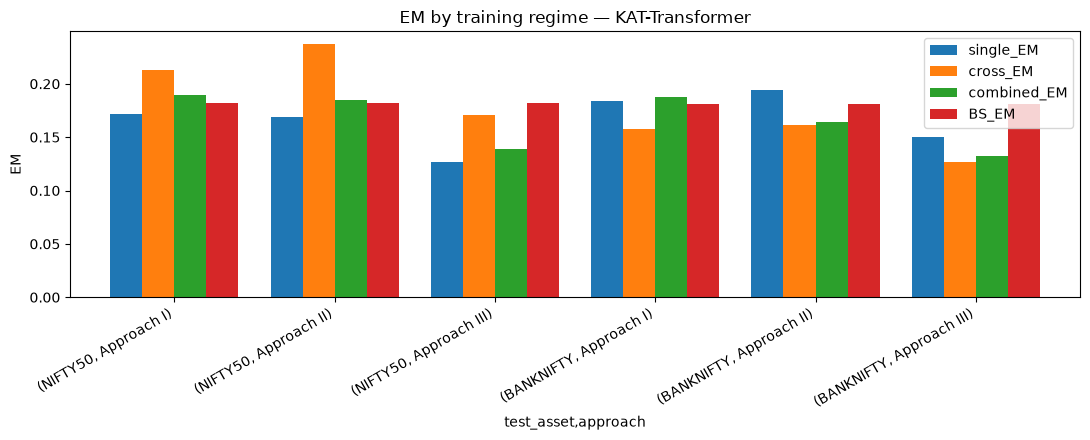


Best regime per (asset, approach):
test_asset  approach    
NIFTY50     Approach I      single_EM
            Approach II     single_EM
            Approach III    single_EM
BANKNIFTY   Approach I       cross_EM
            Approach II      cross_EM
            Approach III     cross_EM
Name: lowest_EM, dtype: str


In [59]:
summary_rows = []
for name in ASSETS:
    for ap in APPROACHES:
        s = single_results.loc[(name, ap)]
        row = {'test_asset': name, 'approach': ap,
               'single_EM': s['EM'], 'single_rho': s['rho']}
        if MULTI_ASSET:
            other = [a for a in ASSETS if a != name][0]
            c = cross_results.loc[(other, name, ap)]
            row.update(cross_EM=c['EM'], cross_rho=c['rho'],
                       combined_EM=combined_results.loc[(ap, name), 'EM'],
                       combined_rho=combined_results.loc[(ap, name), 'rho'])
        row.update(BS_EM=BS[name]['EM'], BS_rho=BS[name]['rho'])
        summary_rows.append(row)

summary = pd.DataFrame(summary_rows).set_index(['test_asset', 'approach']).round(4)
print("=== EM / rho by training regime (lower is better) ===")
print(summary)

em_cols = [c for c in summary.columns if c.endswith('_EM')]
ax = summary[em_cols].plot(kind='bar', figsize=(11, 4.5), width=0.8)
ax.set_ylabel('EM'); ax.set_title('EM by training regime — KAT-Transformer')
ax.axhline(0, color='black', lw=0.6)
plt.xticks(rotation=30, ha='right'); plt.tight_layout(); plt.show()

if MULTI_ASSET:
    print("\nBest regime per (asset, approach):")
    print(summary[em_cols].idxmin(axis=1).rename('lowest_EM'))

## Experiment 6 — Prediction-band diagnostics (Figs. 11 and 14)

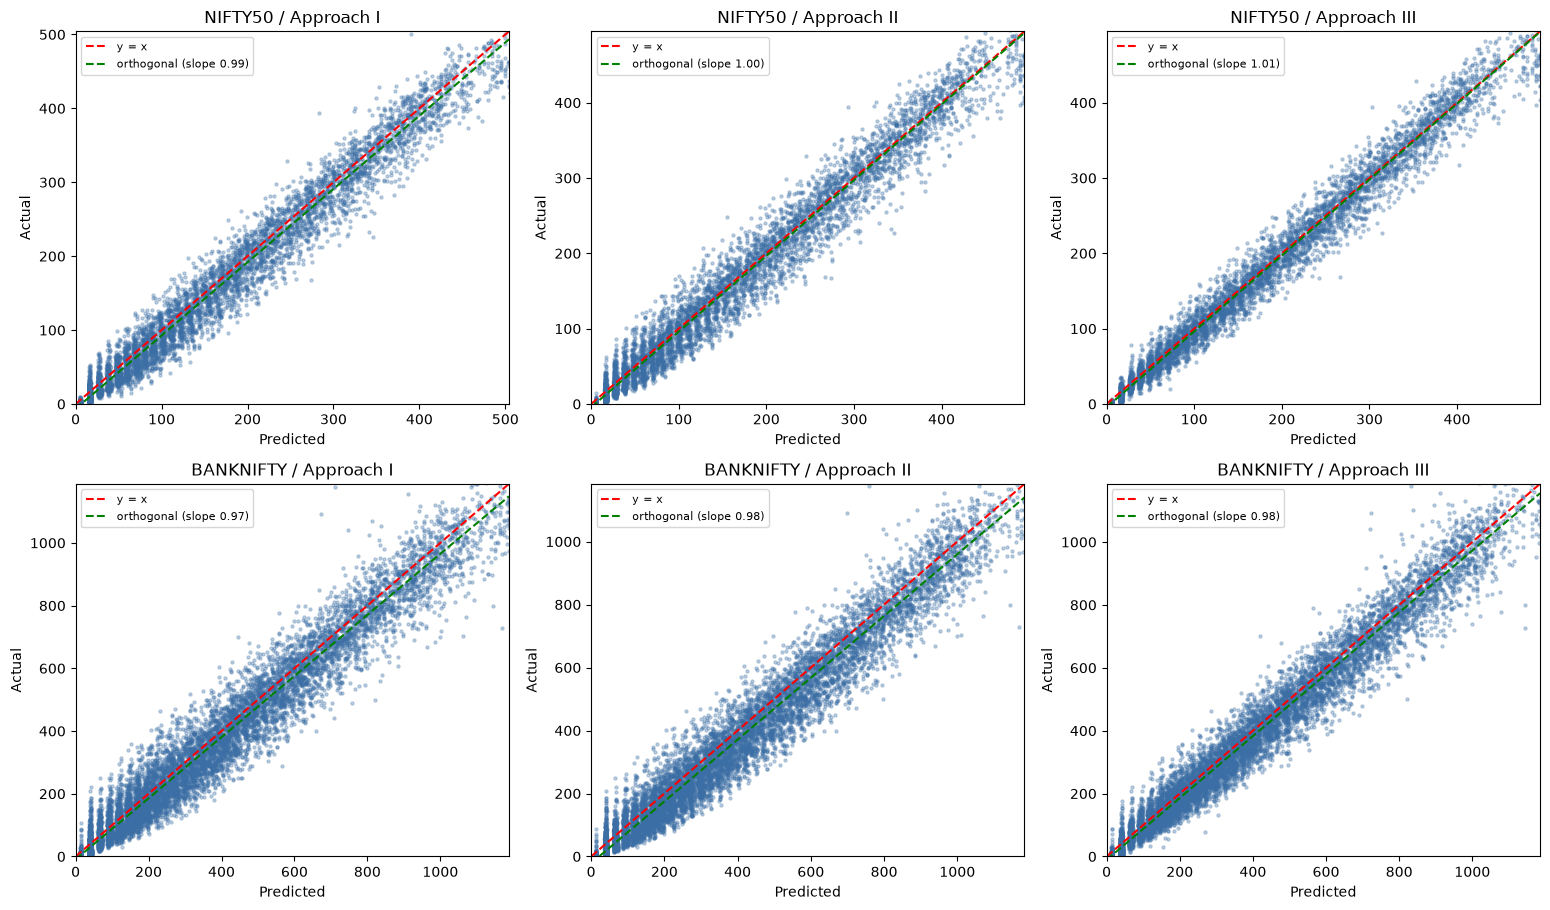

=== Band coverage and bias ===
                        P(|err|<=2)  P(|err|<=5)   q02  q98  tls_slope  mean_signed_error
asset     approach                                                                       
NIFTY50   Approach I         0.7681       0.9689 -6.00  4.0     0.9914             7.9621
          Approach II        0.7626       0.9704 -5.00  5.0     1.0048             3.5833
          Approach III       0.8626       0.9855 -4.00  4.0     1.0070             3.1451
BANKNIFTY Approach I         0.7360       0.9566 -6.00  5.0     0.9745            18.3809
          Approach II        0.7167       0.9529 -6.00  4.0     0.9814            28.1120
          Approach III       0.8113       0.9741 -5.56  4.0     0.9836            16.3903

1 - rho is the confidence the true bin lies in [P-2, P+2];
mean_signed_error near zero means no systematic over/under-pricing.


In [60]:
def orthogonal_regression(x, y):
    x, y = np.asarray(x, float), np.asarray(y, float)
    m = np.isfinite(x) & np.isfinite(y)
    x, y = x[m], y[m]
    xm, ym = x.mean(), y.mean()
    _, _, vt = np.linalg.svd(np.column_stack([x-xm, y-ym]), full_matrices=False)
    vx, vy = vt[0]
    slope = vy/vx
    return slope, ym - slope*xm


def bin_to_price(bins, strike):
    return (np.asarray(bins, float) - 0.5) * W_BIN * np.asarray(strike, float) / 100.0


diag_rows = []
fig, axes = plt.subplots(len(ASSETS), len(APPROACHES), figsize=(5.2*len(APPROACHES), 4.6*len(ASSETS)),
                         squeeze=False)
for i, name in enumerate(ASSETS):
    d_test = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
    for j, ap in enumerate(APPROACHES):
        p = SINGLE_PRED[(name, ap)]
        err = p['y_true'].astype(float) - p['pred'].astype(float)
        pred_px = bin_to_price(p['pred'], d_test['strike'].values)
        act_px = d_test['close'].values
        slope, intercept = orthogonal_regression(pred_px, act_px)

        ax = axes[i][j]
        lim = np.nanpercentile(np.concatenate([pred_px, act_px]), 99.5)
        ax.scatter(pred_px, act_px, s=5, alpha=0.3, color='#3b6ea5')
        xs = np.linspace(0, lim, 50)
        ax.plot(xs, xs, 'r--', label='y = x')
        ax.plot(xs, slope*xs + intercept, 'g--', label=f'orthogonal (slope {slope:.2f})')
        ax.set_xlim(0, lim); ax.set_ylim(0, lim)
        ax.set_title(f'{name} / {ap}'); ax.set_xlabel('Predicted'); ax.set_ylabel('Actual')
        ax.legend(fontsize=8)

        diag_rows.append({'asset': name, 'approach': ap,
                          'P(|err|<=2)': np.mean(np.abs(err) <= 2),
                          'P(|err|<=5)': np.mean(np.abs(err) <= 5),
                          'q02': np.percentile(err, 2), 'q98': np.percentile(err, 98),
                          'tls_slope': slope, 'mean_signed_error': np.mean(pred_px - act_px)})
plt.tight_layout(); plt.show()

diagnostics = pd.DataFrame(diag_rows).set_index(['asset', 'approach']).round(4)
print("=== Band coverage and bias ===")
print(diagnostics)
print("\n1 - rho is the confidence the true bin lies in [P-2, P+2];")
print("mean_signed_error near zero means no systematic over/under-pricing.")

## Experiment 7 — COVID-period test (paper Sec. 7, Table 11, Figs. 17-18)

Same procedure as the paper: take the models trained on **2015-2017** data (single-asset NIFTY50 and
the combined NIFTY50+BANKNIFTY model, Approach III) and score them, **without retraining**, on
**Jan 2019 - Apr 2020** option data, which spans the 2020 crash. Four pieces:

1. **Q-Q plot (Fig. 17)** - log-return distribution Oct-Dec 2019 vs Jan-Mar 2020, showing the regime shift.
2. **EM / rho vs Black-Scholes (Table 11)** - plus a pre-crash / crash split so you can see where the error comes from.
3. **IV prediction band (Fig. 18)** - the predicted bins `[P-2, P+2]` converted to an implied-vol band and compared with the market's average IV.
4. **2018 vs COVID band coverage** - paper reports about 90% coverage on 2018 data and about 75% in the COVID window.

The bin edges (`CUTOFF_BIN`, `NUM_CLASSES`) and the feature standardisation are the *training-time* ones; nothing is refit on COVID data.

In [61]:
# ---- build the COVID-window datasets with the TRAINING bins (never recomputed) -------------------
def assign_bins(d):
    d['output_ratio'] = 100 * d['close'] / d['strike']
    raw = np.ceil(d['output_ratio'] / W_BIN).astype(int).clip(lower=1)
    d['bin_label'] = np.where(raw > CUTOFF_BIN, NUM_CLASSES, raw)
    return d

COVID_DATA, COVID_FEATS = {}, {}
if RUN_COVID:
    for name, files in COVID_FILES.items():
        d, _ = build_asset_dataset(name, files, bonds, date_min=COVID_START, date_max=COVID_END)
        d = assign_bins(d)
        d['hist_vol'] = log_returns_from_lookback(d, 'close').std(axis=1, ddof=1) * np.sqrt(252)
        COVID_DATA[name] = d
        COVID_FEATS[name] = {ap: APPROACH_BUILDERS[ap](d) for ap in COVID_APPROACHES}
        for ap in COVID_APPROACHES:      # must match the training matrices column for column
            assert list(COVID_FEATS[name][ap].columns) == list(FEATURES[name][ap].columns), (name, ap)
        print(f"[{name}] overflow-bin share in COVID window: {100*(d['bin_label']==NUM_CLASSES).mean():.2f}% "
              f"(training data: {100*(DATA[name]['bin_label']==NUM_CLASSES).mean():.2f}%)")
else:
    print("RUN_COVID = False -> skipped")

[NIFTY50] raw=685,439  filtered=11,580  (2019-01-02 to 2020-04-30)
[NIFTY50] overflow-bin share in COVID window: 3.68% (training data: 2.41%)
[BANKNIFTY] raw=292,082  filtered=12,541  (2019-01-01 to 2020-04-30)
[BANKNIFTY] overflow-bin share in COVID window: 3.70% (training data: 2.55%)


[NIFTY50] annualised realised vol  train 0.143 | Oct-Dec 2019 0.101 | Jan-Mar 2020 0.486
[BANKNIFTY] annualised realised vol  train 0.194 | Oct-Dec 2019 0.164 | Jan-Mar 2020 0.574


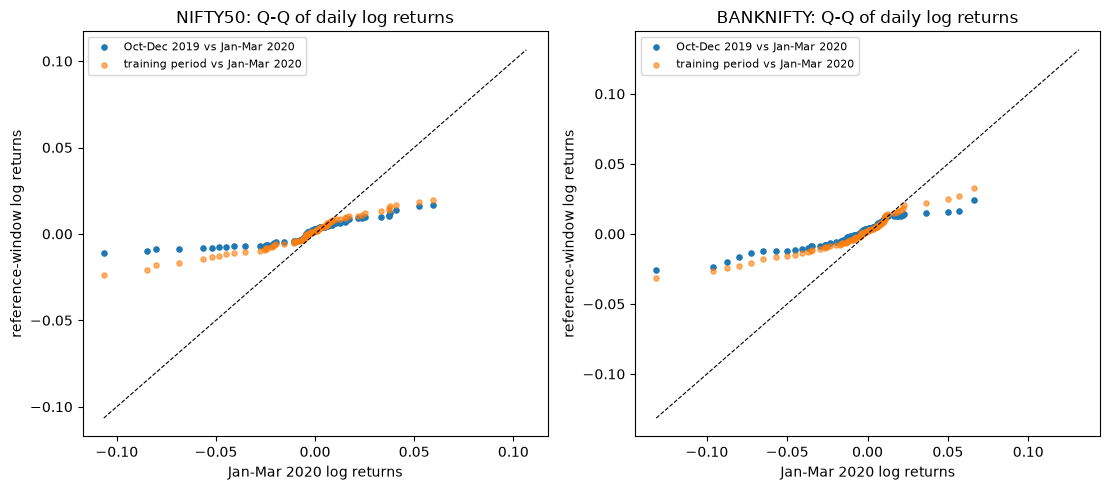

In [62]:
# ---- Fig. 17: Q-Q of daily log returns, Oct-Dec 2019 vs Jan-Mar 2020 -------------------------------
def window_returns(spot_path, start, end):
    sp = load_spot(spot_path).set_index('date')['spot_close']
    lr = np.log(sp).diff().dropna()
    return lr[(lr.index >= start) & (lr.index <= end)]

if RUN_COVID:
    fig, axes = plt.subplots(1, len(COVID_FILES), figsize=(5.6*len(COVID_FILES), 5), squeeze=False)
    qs = np.linspace(0.01, 0.99, 99)
    for ax, (name, files) in zip(axes[0], COVID_FILES.items()):
        pre   = window_returns(files['spot'], '2019-10-01', '2019-12-31')
        crash = window_returns(files['spot'], '2020-01-01', '2020-03-31')
        train = window_returns(files['spot'], DATA_START or '2015-01-01', TRAIN_END)
        ax.scatter(np.quantile(crash, qs), np.quantile(pre, qs), s=14, label='Oct-Dec 2019 vs Jan-Mar 2020')
        ax.scatter(np.quantile(crash, qs), np.quantile(train, qs), s=14, alpha=0.6, label='training period vs Jan-Mar 2020')
        lim = max(abs(np.quantile(crash, [0.01, 0.99])).max(), 0.05)
        ax.plot([-lim, lim], [-lim, lim], 'k--', lw=0.8)
        ax.set_xlabel('Jan-Mar 2020 log returns'); ax.set_ylabel('reference-window log returns')
        ax.set_title(f'{name}: Q-Q of daily log returns'); ax.legend(fontsize=8)
        ann = lambda r: r.std(ddof=1) * np.sqrt(252)
        print(f"[{name}] annualised realised vol  train {ann(train):.3f} | Oct-Dec 2019 {ann(pre):.3f} | Jan-Mar 2020 {ann(crash):.3f}")
    plt.tight_layout(); plt.show()

In [63]:
# ---- Table 11: EM / rho on the COVID window, KAT models vs Black-Scholes ---------------------------
def covid_models(name, ap):
    """Pre-trained bundles to test: the asset's own single model and the combined model."""
    out = {f'{name} (single)': SINGLE_BUNDLES[(name, ap)]}
    if MULTI_ASSET and ap in COMBINED_BUNDLES:
        out['Combined'] = COMBINED_BUNDLES[ap]
    return out

def period_masks(d):
    crash = (d['date'] >= pd.Timestamp(CRASH_START)).values
    return {'Full window': np.ones(len(d), bool), 'Pre-crash': ~crash, 'Crash': crash}

COVID_PRED, covid_rows = {}, []
if RUN_COVID:
    for name, d in COVID_DATA.items():
        bs_price = black_scholes_call(d['underlying'], d['strike'], d['time_to_maturity_yrs'],
                                      d['risk_free_rate'] / 100, d['hist_vol'])
        bs_bin = price_to_bin(bs_price, d['strike'])
        for ap in COVID_APPROACHES:
            X, y, cols = split_xy(COVID_FEATS[name][ap], np.ones(len(d), bool))
            for label, b in covid_models(name, ap).items():
                assert b['columns'] == cols, f"feature mismatch for {label}"
                pred, _ = score(b, X, y)
                COVID_PRED[(name, ap, label)] = pred
                for pname, pm in period_masks(d).items():
                    if pm.sum() == 0:
                        continue
                    covid_rows.append({'asset': name, 'approach': ap, 'model': label, 'period': pname,
                                       'n': int(pm.sum()), 'EM': em_metric(y[pm], pred[pm]),
                                       'rho': rho_metric(y[pm], pred[pm]), 'A': acc_metric(y[pm], pred[pm])})
            for pname, pm in period_masks(d).items():
                if pm.sum() == 0:
                    continue
                covid_rows.append({'asset': name, 'approach': ap, 'model': 'Black-Scholes', 'period': pname,
                                   'n': int(pm.sum()), 'EM': em_metric(y[pm], bs_bin[pm]),
                                   'rho': rho_metric(y[pm], bs_bin[pm]), 'A': acc_metric(y[pm], bs_bin[pm])})

    covid_results = (pd.DataFrame(covid_rows)
                     .set_index(['asset', 'approach', 'period', 'model']).sort_index().round(4))
    print("=== Table 11: models trained on 2015-2017, tested on the COVID window ===")
    print(covid_results)

    print("\nReference - same models on the 2017-18 test set (Experiment 1 / 4):")
    for name in COVID_DATA:
        for ap in COVID_APPROACHES:
            s_ = single_results.loc[(name, ap)]
            line = f"  {name} {ap}: single EM {s_['EM']:.4f} rho {s_['rho']:.4f}"
            if MULTI_ASSET and (ap, name) in combined_results.index:
                c_ = combined_results.loc[(ap, name)]
                line += f" | combined EM {c_['EM']:.4f} rho {c_['rho']:.4f}"
            print(line + f" | B-S EM {BS[name]['EM']:.4f} rho {BS[name]['rho']:.4f}")

=== Table 11: models trained on 2015-2017, tested on the COVID window ===
                                                           n      EM     rho       A
asset     approach     period      model                                            
BANKNIFTY Approach III Crash       BANKNIFTY (single)    514  1.4016  0.8638  0.0350
                                   Black-Scholes         514  0.7035  0.6109  0.3482
                                   Combined              514  1.3307  0.8794  0.0486
                       Full window BANKNIFTY (single)  12541  0.2661  0.2997  0.2335
                                   Black-Scholes       12541  0.3313  0.3977  0.1970
                                   Combined            12541  0.2483  0.2720  0.2647
                       Pre-crash   BANKNIFTY (single)  12027  0.2176  0.2755  0.2420
                                   Black-Scholes       12027  0.3154  0.3885  0.1906
                                   Combined            12027  0.2020  0.2460

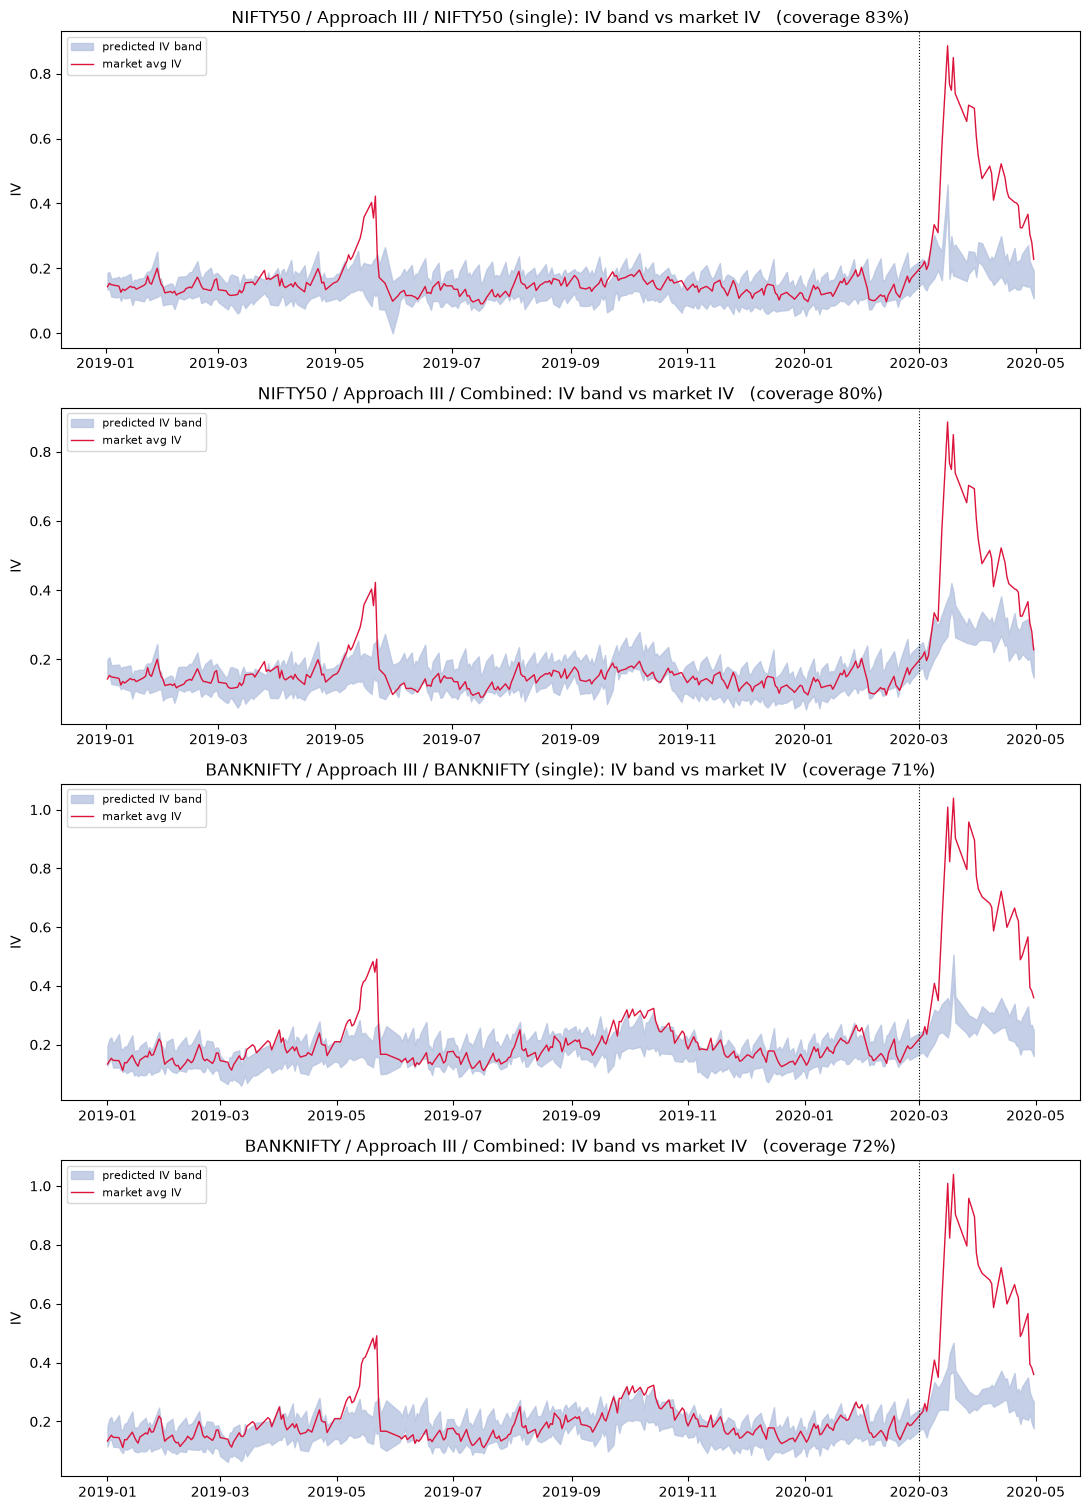

=== Share of days the market IV lies inside the predicted band (paper: ~90% in 2018, ~75% in COVID) ===
                                                           band_coverage
asset     approach     model              window                        
NIFTY50   Approach III NIFTY50 (single)   COVID (full)             0.826
                                          COVID pre-crash          0.917
                                          COVID crash              0.088
                                          2017-18 test             0.910
                       Combined           COVID (full)             0.797
                                          COVID pre-crash          0.881
                                          COVID crash              0.118
BANKNIFTY Approach III BANKNIFTY (single) COVID (full)             0.706
                                          COVID pre-crash          0.783
                                          COVID crash              0.061
                    

In [64]:
# ---- Fig. 18: predicted IV band vs market IV, and band coverage ---------------------------------------
def implied_vol_call(price, S, K, T, r, lo=1e-4, hi=5.0, iters=60):
    """Vectorised bisection on the Black-Scholes call price. NaN where no IV exists."""
    price, S, K, T, r = [np.asarray(x, float) for x in (price, S, K, T, r)]
    intrinsic = np.maximum(S - K * np.exp(-r * T), 0.0)
    valid = (price > intrinsic + 1e-8) & (price < S)
    a, b = np.full(price.shape, lo), np.full(price.shape, hi)
    for _ in range(iters):
        m = 0.5 * (a + b)
        too_high = black_scholes_call(S, K, T, r, m) > price
        b = np.where(too_high, m, b)
        a = np.where(too_high, a, m)
    iv = 0.5 * (a + b)
    iv[~valid | (iv > hi - 1e-3)] = np.nan
    return iv


def iv_band_frame(d, pred_bins):
    """Daily market IV (from the actual close) and the IV of the lower / upper edge of the
    predicted band [P-2, P+2], averaged per day over the near-ATM contracts (paper Sec. 5.2)."""
    K = d['strike'].values
    S = d['underlying'].values
    T = d['time_to_maturity_yrs'].values
    r = d['risk_free_rate'].values / 100
    lo_px = np.clip((pred_bins - 3), 0, None) * W_BIN * K / 100.0      # lower edge of bin P-2
    hi_px = (pred_bins + 2) * W_BIN * K / 100.0                         # upper edge of bin P+2
    f = pd.DataFrame({'date': d['date'].values,
                      'iv_mkt': implied_vol_call(d['close'].values, S, K, T, r),
                      'iv_lo':  implied_vol_call(lo_px, S, K, T, r),
                      'iv_hi':  implied_vol_call(hi_px, S, K, T, r)})
    return f.groupby('date').mean().dropna(subset=['iv_mkt', 'iv_hi'])   # lower edge may be NaN near 0 price


def band_coverage(f):
    lo = f['iv_lo'].fillna(0.0)
    return float(((f['iv_mkt'] >= lo) & (f['iv_mkt'] <= f['iv_hi'])).mean())


if RUN_COVID:
    cov_rows = []
    keys = list(COVID_PRED)
    fig, axes = plt.subplots(len(keys), 1, figsize=(11, 3.8*len(keys)), squeeze=False)
    for ax, (name, ap, label) in zip(axes[:, 0], keys):
        d = COVID_DATA[name]
        f = iv_band_frame(d, COVID_PRED[(name, ap, label)])
        ax.fill_between(f.index, f['iv_lo'].fillna(0), f['iv_hi'], color='#b7c4e0', alpha=0.8, label='predicted IV band')
        ax.plot(f.index, f['iv_mkt'], color='crimson', lw=1, label='market avg IV')
        ax.axvline(pd.Timestamp(CRASH_START), color='k', ls=':', lw=0.8)
        cov_all = band_coverage(f)
        crash_f = f[f.index >= pd.Timestamp(CRASH_START)]
        pre_f   = f[f.index <  pd.Timestamp(CRASH_START)]
        cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': 'COVID (full)', 'band_coverage': cov_all})
        if len(pre_f):   cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': 'COVID pre-crash', 'band_coverage': band_coverage(pre_f)})
        if len(crash_f): cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': 'COVID crash', 'band_coverage': band_coverage(crash_f)})

        # reference: same model on the 2017-18 test set (paper reports ~90%)
        if label == f'{name} (single)' and (name, ap) in SINGLE_PRED:
            d_te = DATA[name].loc[SPLIT[name]['test']].reset_index(drop=True)
            cov_rows.append({'asset': name, 'approach': ap, 'model': label, 'window': '2017-18 test',
                             'band_coverage': band_coverage(iv_band_frame(d_te, SINGLE_PRED[(name, ap)]['pred']))})
        ax.set_title(f'{name} / {ap} / {label}: IV band vs market IV   (coverage {cov_all:.0%})')
        ax.set_ylabel('IV'); ax.legend(loc='upper left', fontsize=8)
    plt.tight_layout(); plt.show()

    band_table = pd.DataFrame(cov_rows).set_index(['asset', 'approach', 'model', 'window']).round(3)
    print("=== Share of days the market IV lies inside the predicted band (paper: ~90% in 2018, ~75% in COVID) ===")
    print(band_table)
    print("\nThe model misses where IV jumps sharply - sentiment shifts that the 2015-2017 training data never contained.")

## Summary

In [66]:
print("=" * 80)
print("SINGLE-ASSET (Tables 4/5)"); print(single_results[['EM', 'rho', 'A']])
print("\nBLACK-SCHOLES BENCHMARK"); print(bs_table)
if MULTI_ASSET:
    print("\nCROSS-ASSET (Table 8)"); print(cross_results[['EM', 'rho']])
    print("\nCOMBINED / MULTI-ASSET (Table 9)"); print(combined_results[['EM', 'rho']])
print("\nALL REGIMES"); print(summary)
print("\nBAND COVERAGE / BIAS"); print(diagnostics[['P(|err|<=2)', 'mean_signed_error']])
if RUN_COVID and 'covid_results' in globals():
    print("\nCOVID WINDOW (Table 11)"); print(covid_results[['n', 'EM', 'rho']])
    print("\nIV BAND COVERAGE"); print(band_table)
print("=" * 80)

with pd.ExcelWriter('result/kat_results_old.xlsx') as xl:
    single_results.to_excel(xl, sheet_name='single_asset')
    bs_table.to_excel(xl, sheet_name='black_scholes')
    if MULTI_ASSET:
        cross_results.to_excel(xl, sheet_name='cross_asset')
        combined_results.to_excel(xl, sheet_name='combined')
    summary.to_excel(xl, sheet_name='all_regimes')
    if RUN_COVID:
        covid_results.to_excel(xl, sheet_name='covid_table11')
        band_table.to_excel(xl, sheet_name='covid_iv_band')
    diagnostics.to_excel(xl, sheet_name='diagnostics')
print("results written to result/kat_results_old.xlsx")

SINGLE-ASSET (Tables 4/5)
                            EM     rho       A
asset     approach                            
NIFTY50   Approach I    0.1716  0.2319  0.2015
          Approach II   0.1686  0.2374  0.2235
          Approach III  0.1268  0.1374  0.2877
BANKNIFTY Approach I    0.1842  0.2640  0.2007
          Approach II   0.1943  0.2833  0.1717
          Approach III  0.1505  0.1887  0.2559

BLACK-SCHOLES BENCHMARK
               EM     rho       A
NIFTY50    0.1819  0.2637  0.2461
BANKNIFTY  0.1815  0.2702  0.2484

CROSS-ASSET (Table 8)
                                       EM     rho
trained_on tested_on approach                    
NIFTY50    BANKNIFTY Approach I    0.1580  0.2065
                     Approach II   0.1615  0.2031
                     Approach III  0.1267  0.1438
BANKNIFTY  NIFTY50   Approach I    0.2132  0.3361
                     Approach II   0.2373  0.3877
                     Approach III  0.1707  0.2348

COMBINED / MULTI-ASSET (Table 9)
              